# Card 07 – Marketing
**Question:** does the marketing money bring real orders?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

all years: 23,958,433 orders claimed by campaigns vs 535,359 real orders = ×44.8


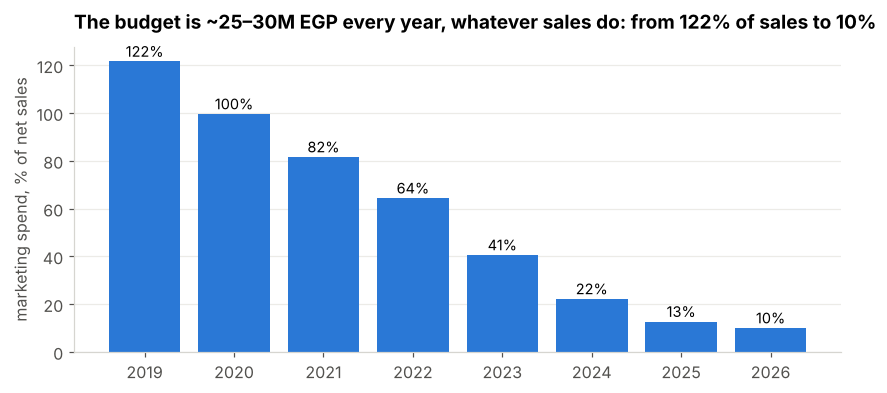

,spend_M,net_sales_M,orders_attributed,real_orders,spend_%_of_sales,attributed_per_real
fy,,,,,,
2019,23.3,19.2,2949554,40319,121.6,73.2
2020,24.5,24.6,2659633,45523,99.6,58.4
2021,25.3,31.0,3114384,51674,81.6,60.3
2022,29.8,46.3,3035681,59343,64.3,51.2
2023,30.1,74.2,3242989,69195,40.6,46.9
2024,29.0,131.0,2821492,79327,22.2,35.6
2025,26.8,211.3,3115710,90144,12.7,34.6
2026,28.9,289.2,3018990,99834,10.0,30.2


In [2]:
mk, so = full_years(files['campaigns']), full_years(files['orders'])
y = pd.DataFrame({'spend_M': mk.groupby('fy').spend_EGP.sum() / 1e6, 'net_sales_M': so.groupby('fy').net_before_tax_EGP.sum() / 1e6,
                  'orders_attributed': mk.groupby('fy').orders_attributed.sum(), 'real_orders': so.groupby('fy').size()})
y['spend_%_of_sales'] = y.spend_M / y.net_sales_M * 100
y['attributed_per_real'] = y.orders_attributed / y.real_orders
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(y.index, y['spend_%_of_sales'], color=BLUE)
for x, v in y['spend_%_of_sales'].items():
    ax.text(x, v + 2, f'{v:.0f}%', ha='center', fontsize=9.5)
ax.set_xticks(y.index)
style(ax, 'The budget is ~25–30M EGP every year, whatever sales do: from 122% of sales to 10%', 'marketing spend, % of net sales')
save(fig, 'c07_spend_vs_sales')
print(f'all years: {mk.orders_attributed.sum():,} orders claimed by campaigns vs {len(so):,} real orders = ×{mk.orders_attributed.sum() / len(so):.1f}')
y.round(1)

In [3]:
ch = mk.groupby('channel').agg(spend=('spend_EGP', 'sum'), impressions=('impressions', 'sum'), clicks=('clicks', 'sum'), claimed=('orders_attributed', 'sum'))
ch['CPC_EGP'] = ch.spend / ch.clicks
ch['CTR_%'] = ch.clicks / ch.impressions * 100
ch['claimed_per_click_%'] = ch.claimed / ch.clicks * 100
ch['share_of_spend_%'] = ch.spend / ch.spend.sum() * 100
ch.round(3).sort_values('CPC_EGP')

,spend,impressions,clicks,claimed,CPC_EGP,CTR_%,claimed_per_click_%,share_of_spend_%
channel,,,,,,,,
Meta Ads,38071761.35,1925569103,90204865,4563858,0.422,4.685,5.059,17.500
In-store,35997704.06,1833826645,83822790,4292084,0.429,4.571,5.120,16.547
Google Ads,37425834.16,1892846306,82625315,4031772,0.453,4.365,4.880,17.203
Outdoor,37296226.47,1769246190,79354566,3742299,0.470,4.485,4.716,17.144
SMS / CRM,33622015.03,1579935157,69251026,3627373,0.486,4.383,5.238,15.455
Influencers,35136043.25,1668387796,70859307,3701047,0.496,4.247,5.223,16.151


All six channels cost ~0.42–0.50 EGP per click with CTR 4.2–4.7%, and every channel claims ~5% of its clicks as orders.
So the data cannot say which channel works – it only says the budget is split equally.

correlation spend ↔ real orders, governorate × month: 0.062


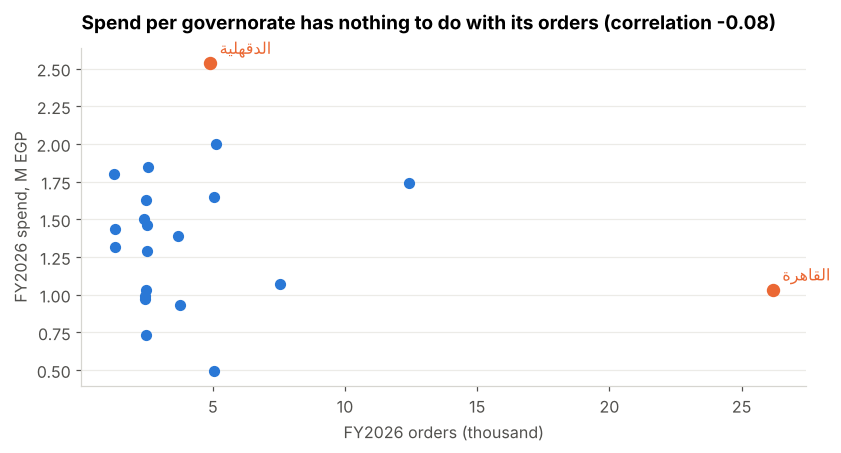

spend,lowest 25% spend,2,3,highest 25% spend
avg orders in that governorate-month,222.0,280.0,266.0,284.0


In [4]:
br = files['branches'][['branch_id', 'governorate_ar']]
o_g = so.merge(br, on='branch_id')
g = pd.DataFrame({'spend_M': mk[mk.fy == 2026].groupby('governorate_ar').spend_EGP.sum() / 1e6,
                  'orders': o_g[o_g.fy == 2026].groupby('governorate_ar').size()}).dropna()
r = g.corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(g.orders / 1e3, g.spend_M, color=BLUE, s=40)
for name in [g.orders.idxmax(), g.spend_M.idxmax()]:
    ax.scatter(g.orders[name] / 1e3, g.spend_M[name], color=ORANGE, s=60)
    ax.annotate(name, (g.orders[name] / 1e3, g.spend_M[name]), textcoords='offset points', xytext=(6, 6), color=ORANGE)
style(ax, f'Spend per governorate has nothing to do with its orders (correlation {r:.2f})', 'FY2026 spend, M EGP')
ax.set_xlabel('FY2026 orders (thousand)')
save(fig, 'c07_spend_vs_orders_gov')
mk['month'] = mk.start_date.dt.to_period('M').dt.to_timestamp()
gm = pd.DataFrame({'spend': mk.groupby(['governorate_ar', 'month']).spend_EGP.sum(),
                   'orders': o_g.groupby(['governorate_ar', 'month']).size()}).dropna()
print('correlation spend ↔ real orders, governorate × month:', round(gm.corr().iloc[0, 1], 3))
q = gm.groupby(pd.qcut(gm.spend, 4, labels=['lowest 25% spend', '2', '3', 'highest 25% spend']), observed=True).orders.mean()
q.round(0).to_frame('avg orders in that governorate-month').T

In [5]:
g['% of spend'] = g.spend_M / g.spend_M.sum() * 100
g['% of orders'] = g.orders / g.orders.sum() * 100
g['budget if it followed orders (M)'] = g['% of orders'] / 100 * g.spend_M.sum()
g.sort_values('orders', ascending=False).round(2).head(8)

,spend_M,orders,% of spend,% of orders,budget if it followed orders (M)
governorate_ar,,,,,
القاهرة,1.03,26193,3.58,26.24,7.57
الإسكندرية,1.74,12409,6.04,12.43,3.59
الجيزة,1.07,7536,3.70,7.55,2.18
الغربية,2.00,5118,6.92,5.13,1.48
البحيرة,0.49,5061,1.71,5.07,1.46
المنيا,1.65,5053,5.71,5.06,1.46
الدقهلية,2.54,4910,8.79,4.92,1.42
المنوفية,0.93,3765,3.23,3.77,1.09


In [6]:
s26 = y.spend_M.loc[2026]
pd.DataFrame({'cut spend with no measured effect': ['10%', '20%', '25%', '30%'],
              'saved / year (M EGP)': [round(s26 * p, 2) for p in [0.10, 0.20, 0.25, 0.30]]})

,cut spend with no measured effect,saved / year (M EGP)
0,10%,2.89
1,20%,5.77
2,25%,7.21
3,30%,8.66


### Takeaway (card 07)
- Campaigns claim **~×45** the real orders → attributed orders are not a KPI.
- The budget is fixed (~25–30M/yr) and split evenly across channels and governorates: Cairo has 26% of the orders and 3.6% of the budget.
- Spend has no visible link with real orders (≈0 at governorate-month level).
- Fix: (1) one marketing ledger (finance shows 11.8M, campaigns 219.5M); (2) **holdout tests** – stop ads in matched governorates for 4 weeks and measure;
  (3) budget follows demand; (4) cut ~25% of spend that shows no effect = **~7.2M EGP/year**, reinvest only what tests prove.